<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/fyp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [77]:
df = pd.DataFrame(pd.read_csv('/content/prevalence-by-mental-and-substance-use-disorder.csv'))
#df.head()

In [78]:
df.columns = ['country', 'code', 'year', 'schiz', 'bipolar', 'ed', 'anxiety', 'drug_use', 'depressive', 'alcohol']
df.head(3)

,country,code,year,schiz,bipolar,ed,anxiety,drug_use,depressive,alcohol
0,Afghanistan,AFG,1990,0.228979,0.721207,0.131001,4.835127,0.454202,5.125291,0.444036
1,Afghanistan,AFG,1991,0.228120,0.719952,0.126395,4.821765,0.447112,5.116306,0.444250
2,Afghanistan,AFG,1992,0.227328,0.718418,0.121832,4.801434,0.441190,5.106558,0.445501


EDA

<Axes: xlabel='year'>

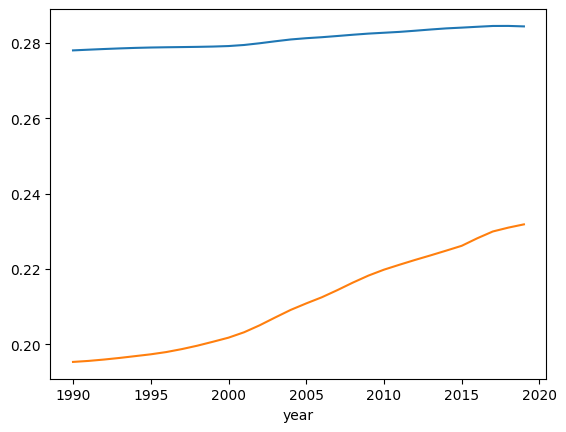

In [79]:
df.groupby('year')['schiz'].mean().plot()
df.groupby('year')['ed'].mean().plot()

Testing stationarity

In [26]:
from statsmodels.tsa.stattools import adfuller

schiz_year_mean = df.groupby('year')['schiz'].mean()
schiz_year_mean_series = adfuller(pd.Series(schiz_year_mean))[1]
print(schiz_year_mean_series)

#if under 0.05... non-stationary
schiz_year_mean_series > 0.05    #IS STATIONARY... no differencing

0.2358873363613352


/tmp/ipykernel_10858/644825943.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  schiz_year_mean_series = adfuller(pd.Series(schiz_year_mean))[1]


True

In [132]:
adfuller_stats = []
#doesn't work with more countries... seems each point represents country
for num in range(df['country'].nunique()):
  adfuller_stats.append(adfuller(pd.Series(pd.DataFrame(df.groupby('country')['schiz']).iloc[num][1]), result_object = True)[1])

zipped_adfuller = pd.concat(([pd.Series(adfuller_stats),
                              pd.Series(df['country'].unique())]), axis = 1)
stationary_index = np.where(zipped_adfuller.iloc[:, 0] > 0.05)
stationary_df = zipped_adfuller.iloc[stationary_index]
stationary_df

,0,1
1,0.999088,African Region (WHO)
2,0.234480,Albania
3,0.998512,Algeria
4,0.998916,American Samoa
6,0.335163,Angola
...,...,...
221,0.632579,World Bank High Income
222,0.971793,World Bank Low Income
223,0.940264,World Bank Lower Middle Income
224,0.994459,World Bank Upper Middle Income


Differencing function: for NON-STATIONARY... rest of df

Take note of need differencing, for now choose stationary

In [143]:
dfs = df[df['country'].isin(list(stationary_df.iloc[:, 1]))]
dfs.groupby('country')['schiz'].mean()

,schiz
country,
African Region (WHO),0.217597
Albania,0.301066
Algeria,0.262260
American Samoa,0.324998
Angola,0.217549
...,...
World Bank High Income,0.358652
World Bank Low Income,0.219545
World Bank Lower Middle Income,0.279718


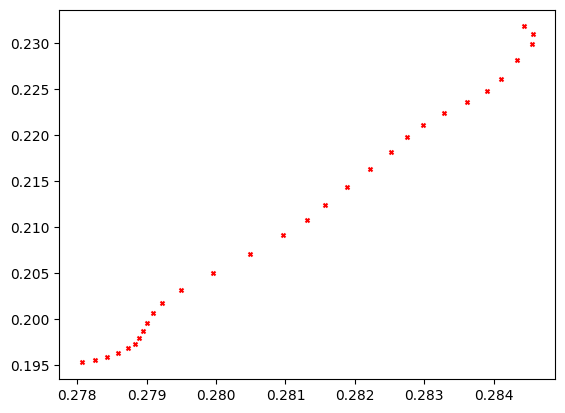

In [6]:
plt.scatter(df.groupby('year')['schiz'].mean(), df.groupby('year')['ed'].mean(), s = 8, color = 'red', marker = 'x')

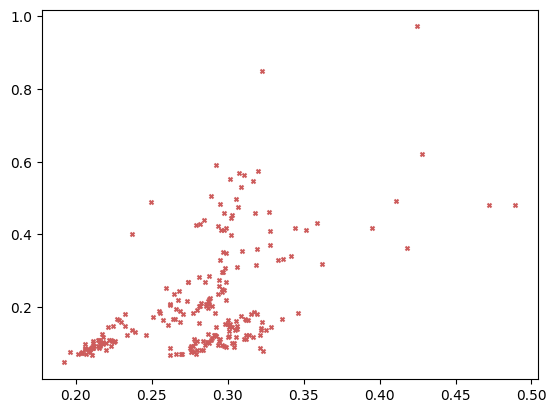

In [7]:
plt.scatter(df.groupby('country')['schiz'].mean(), df.groupby('country')['ed'].mean(), s = 8, color = 'indianred', marker = 'x')

Prep

In [8]:
X = df.drop(columns = ['code', 'country', 'year'])
y = df['schiz']